# NVIDIA vs. Semiconductor Peers: Risk and Return Analysis

## Project objective
Evaluate NVIDIA's historical return and risk relative to selected
semiconductor companies and a broad US stock market benchmark.

## Main research question
Did NVIDIA deliver stronger risk-adjusted performance than its selected
peers, and did the conclusion remain consistent across different years?

## Study period
January 1, 2021–December 31, 2025.

## Selected companies
- NVIDIA (NVDA)
- Advanced Micro Devices (AMD)
- Broadcom (AVGO)
- Intel (INTC)
- Qualcomm (QCOM)

These companies operate within the semiconductor industry but have
different products, customers and business models. They are an industry
comparison group, not identical businesses.

## Benchmarks

- SPY: broad US stock market benchmark.
- SOXX: semiconductor industry benchmark used for sensitivity analysis.

## Performance measures
- Total return
- Compound annual growth rate (CAGR)
- Annualized volatility
- Sharpe ratio
- Beta
- Tracking error
- Maximum drawdown

## Scope
This project evaluates historical performance. It does not forecast
stock prices or establish whether a stock is currently undervalued.

In [50]:
# Project settings

stock_tickers = ["NVDA", "AMD", "AVGO", "INTC", "QCOM"]
benchmark_ticker = "SPY"

start_date = "2021-01-01"
end_date = "2026-01-01" # Exclusive end date; includes December 2025

print("Companies:", stock_tickers)
print("Benchmark:", benchmark_ticker)
print("Study period: January 2021 through December 2025")

Companies: ['NVDA', 'AMD', 'AVGO', 'INTC', 'QCOM']
Benchmark: SPY
Study period: January 2021 through December 2025


## Analytical approach

The five-year study period supports comparisons across different market
conditions. A broad market benchmark provides context for evaluating
each stock's returns and risk.

## Research questions

1. Does the highest-return stock also have the highest Sharpe ratio?
2. Which stock experienced the largest peak-to-trough decline?
3. Do relative performance rankings change from year to year?
4. How sensitive are the conclusions to the benchmark?

## Data acquisition

Daily prices are obtained from Yahoo Finance using the yfinance package.
Adjusted closing prices account for stock splits and dividends.

The analysis covers 2021–2025. A short buffer before the study period is downloaded to calculate the first trading day’s return.

In [51]:
%pip install -q yfinance

In [52]:
import pandas as pd
import yfinance as yf

print("pandas version:", pd.__version__)
print("yfinance version:", yf.__version__)

pandas version: 2.2.3
yfinance version: 0.2.66


In [53]:
all_tickers = stock_tickers + [benchmark_ticker]

download_start = (
    pd.Timestamp(start_date) - pd.Timedelta(days=7)
).strftime("%Y-%m-%d")

raw_data = yf.download(
    tickers=all_tickers,
    start=download_start,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    group_by="column",
    keepna=True,
    progress=False,
)

if raw_data is None or raw_data.empty:
    raise ValueError("No data downloaded. Check the download messages.")

retrieved_at = pd.Timestamp.now(tz="UTC").isoformat()
print("Retrieved at:", retrieved_at)

Retrieved at: 2026-11-15T04:08:16.440049+00:00


In [54]:
prices = (
    raw_data["Adj Close"]
    .reindex(columns=all_tickers)
    .sort_index()
)

prices.index.name = "Date"

display(prices.head())
display(prices.tail())

Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Date,,,,,,
2020-12-28,12.833795,91.599998,38.639286,42.552475,130.613022,344.719421
2020-12-29,12.876821,90.620003,38.385201,44.649807,131.276093,344.061707
2020-12-30,13.078282,92.290001,38.903217,44.071236,132.566818,344.552704
2020-12-31,12.987999,91.709999,39.173409,45.038540,134.679794,346.303253
2021-01-04,13.046196,92.300003,38.043438,44.902935,131.284927,341.588715


Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Date,,,,,,
2025-12-24,188.169678,215.039993,348.300415,36.160000,172.079483,685.029480
2025-12-26,190.085205,214.990005,350.199921,36.200001,172.118866,684.960022
2025-12-29,187.780594,215.610001,347.474945,36.680000,170.760101,682.519043
2025-12-30,187.102173,215.339996,347.932434,37.299999,170.976715,681.685547
2025-12-31,186.064606,214.160004,344.202972,36.900002,168.416748,676.635010


In [55]:
coverage = pd.DataFrame({
    "First valid date": prices.apply(lambda column: column.first_valid_index()),
    "Last valid date": prices.apply(lambda column: column.last_valid_index()),
    "Available prices": prices.notna().sum(),
    "Missing prices": prices.isna().sum(),
})

display(coverage)

print("Duplicate dates:", prices.index.duplicated().sum())
print("Non-positive prices:", int((prices <= 0).sum().sum()))

,First valid date,Last valid date,Available prices,Missing prices
Ticker,,,,
NVDA,2020-12-28,2025-12-31,1259,0
AMD,2020-12-28,2025-12-31,1259,0
AVGO,2020-12-28,2025-12-31,1259,0
INTC,2020-12-28,2025-12-31,1259,0
QCOM,2020-12-28,2025-12-31,1259,0
SPY,2020-12-28,2025-12-31,1259,0


Duplicate dates: 0
Non-positive prices: 0


## Daily return calculation

Simple daily returns are calculated from adjusted closing prices:

Daily return = (Current adjusted close / Previous adjusted close) - 1

Returns are calculated before filtering to the study period, preserving
the first trading day's return in 2021. Missing prices are not filled.
Returns are stored as decimals and displayed as percentages.

In [56]:
daily_returns = prices.pct_change(fill_method=None)

daily_returns = daily_returns.loc[
    (daily_returns.index >= pd.Timestamp(start_date))
    & (daily_returns.index < pd.Timestamp(end_date))
].copy()

display(daily_returns.head().style.format("{:.2%}"))
display(daily_returns.tail().style.format("{:.2%}"))

Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Date,,,,,,
2021-01-04 00:00:00,0.45%,0.64%,-2.88%,-0.30%,-2.52%,-1.36%
2021-01-05 00:00:00,2.22%,0.51%,0.68%,1.89%,2.65%,0.69%
2021-01-06 00:00:00,-5.90%,-2.63%,-0.62%,0.97%,-0.81%,0.60%
2021-01-07 00:00:00,5.78%,5.35%,4.21%,2.13%,2.98%,1.49%
2021-01-08 00:00:00,-0.50%,-0.61%,0.51%,-1.03%,0.60%,0.57%


Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Date,,,,,,
2025-12-24 00:00:00,-0.32%,0.07%,0.26%,-0.52%,0.01%,0.35%
2025-12-26 00:00:00,1.02%,-0.02%,0.55%,0.11%,0.02%,-0.01%
2025-12-29 00:00:00,-1.21%,0.29%,-0.78%,1.33%,-0.79%,-0.36%
2025-12-30 00:00:00,-0.36%,-0.13%,0.13%,1.69%,0.13%,-0.12%
2025-12-31 00:00:00,-0.55%,-0.55%,-1.07%,-1.07%,-1.50%,-0.74%


In [57]:
import numpy as np

return_checks = pd.Series({
    "First return date": daily_returns.index.min().date(),
    "Last return date": daily_returns.index.max().date(),
    "Number of observations": len(daily_returns),
    "Number of tickers": daily_returns.shape[1],
    "Missing values": int(daily_returns.isna().sum().sum()),
    "Infinite values": int(np.isinf(daily_returns.to_numpy()).sum()),
    "Duplicate dates": int(daily_returns.index.duplicated().sum()),
})

display(return_checks.to_frame("Result"))

assert not daily_returns.empty, "The return dataset is empty."
assert np.isfinite(daily_returns.to_numpy()).all(), "Missing or infinite returns found."
assert daily_returns.index.is_unique, "Duplicate dates found."
assert (daily_returns > -1).all().all(), "A return of -100% or lower requires investigation."

,Result
First return date,2021-01-04
Last return date,2025-12-31
Number of observations,1255
Number of tickers,6
Missing values,0
Infinite values,0
Duplicate dates,0


In [58]:
first_return_date = daily_returns.index[0]
previous_date = prices.index[prices.index < first_return_date][-1]

previous_price = prices.loc[previous_date, "NVDA"]
current_price = prices.loc[first_return_date, "NVDA"]

manual_return = current_price / previous_price - 1
calculated_return = daily_returns.loc[first_return_date, "NVDA"]

print(f"Previous date: {previous_date.date()}")
print(f"Previous adjusted close: ${previous_price:.6f}")
print(f"Current date: {first_return_date.date()}")
print(f"Current adjusted close: ${current_price:.6f}")
print(f"Direct calculation: {manual_return:.4%}")
print(f"Pandas calculation: {calculated_return:.4%}")

assert np.isclose(manual_return, calculated_return), "Return calculations do not match."

Previous date: 2020-12-31
Previous adjusted close: $12.987999
Current date: 2021-01-04
Current adjusted close: $13.046196
Direct calculation: 0.4481%
Pandas calculation: 0.4481%


In [59]:
daily_summary = pd.DataFrame({
    "Average daily return": daily_returns.mean(),
    "Daily volatility": daily_returns.std(),
    "Worst daily return": daily_returns.min(),
    "Best daily return": daily_returns.max(),
})

display(daily_summary.style.format("{:.2%}"))

,Average daily return,Daily volatility,Worst daily return,Best daily return
Ticker,,,,
NVDA,0.27%,3.29%,-16.97%,24.37%
AMD,0.12%,3.30%,-13.87%,23.82%
AVGO,0.21%,2.67%,-17.40%,24.43%
INTC,0.03%,2.91%,-26.06%,22.77%
QCOM,0.05%,2.40%,-9.51%,15.19%
SPY,0.06%,1.08%,-5.85%,10.50%


## Performance and risk measures

Total return compounds daily adjusted returns over the study period.
Compound annual growth rate (CAGR) is calculated over the five complete
calendar years from 2021 through 2025.

Annualized volatility uses the sample standard deviation of daily
returns multiplied by the square root of 252 trading days.

Maximum drawdown measures the largest peak-to-trough decline in
cumulative investment value. The initial investment value is included
as a starting peak. Drawdowns are reported as negative percentages.

Results assume dividend reinvestment and exclude transaction costs
and taxes.

In [60]:
trading_days_per_year = 252
study_years = 5

wealth_index = (1 + daily_returns).cumprod()

total_return = wealth_index.iloc[-1] - 1
cagr = wealth_index.iloc[-1] ** (1 / study_years) - 1

growth_summary = pd.DataFrame({
    "Total return": total_return,
    "CAGR": cagr,
})

display(growth_summary.style.format("{:.2%}"))

,Total return,CAGR
Ticker,,
NVDA,1332.59%,70.30%
AMD,133.52%,18.49%
AVGO,778.66%,54.44%
INTC,-18.07%,-3.91%
QCOM,25.05%,4.57%
SPY,95.39%,14.34%


In [61]:
annualized_volatility = (
    daily_returns.std(ddof=1) * np.sqrt(trading_days_per_year)
)

display(
    annualized_volatility
    .to_frame("Annualized volatility")
    .style.format("{:.2%}")
)

,Annualized volatility
Ticker,
NVDA,52.20%
AMD,52.38%
AVGO,42.32%
INTC,46.22%
QCOM,38.15%
SPY,17.12%


In [62]:
running_peak = wealth_index.cummax().clip(lower=1.0)

drawdowns = wealth_index / running_peak - 1
max_drawdown = drawdowns.min()

display(
    max_drawdown
    .to_frame("Maximum drawdown")
    .style.format("{:.2%}")
)

,Maximum drawdown
Ticker,
NVDA,-66.34%
AMD,-65.45%
AVGO,-41.15%
INTC,-70.80%
QCOM,-44.29%
SPY,-24.50%


In [63]:
performance_summary = pd.DataFrame({
    "Total return": total_return,
    "CAGR": cagr,
    "Annualized volatility": annualized_volatility,
    "Maximum drawdown": max_drawdown,
})

performance_summary.index.name = "Ticker"

display(
    performance_summary
    .sort_values("CAGR", ascending=False)
    .style.format("{:.2%}")
)

,Total return,CAGR,Annualized volatility,Maximum drawdown
Ticker,,,,
NVDA,1332.59%,70.30%,52.20%,-66.34%
AVGO,778.66%,54.44%,42.32%,-41.15%
AMD,133.52%,18.49%,52.38%,-65.45%
SPY,95.39%,14.34%,17.12%,-24.50%
QCOM,25.05%,4.57%,38.15%,-44.29%
INTC,-18.07%,-3.91%,46.22%,-70.80%


In [64]:
baseline_date = prices.index[
    prices.index < daily_returns.index[0]
][-1]

final_date = daily_returns.index[-1]

price_based_return = (
    prices.loc[final_date] / prices.loc[baseline_date] - 1
)

assert np.allclose(
    total_return.to_numpy(),
    price_based_return.to_numpy(),
), "Compounded returns do not match the adjusted price calculation."

assert np.isfinite(
    performance_summary.to_numpy()
).all(), "The summary contains missing or infinite values."

assert (annualized_volatility >= 0).all(), "Volatility cannot be negative."
assert (max_drawdown <= 0).all(), "Drawdowns must be zero or negative."
assert (max_drawdown > -1).all(), "Drawdowns require investigation."

print("All performance checks passed.")
print(f"Starting price date: {baseline_date.date()}")
print(f"Ending price date: {final_date.date()}")

All performance checks passed.
Starting price date: 2020-12-31
Ending price date: 2025-12-31


## Risk-adjusted and benchmark-relative performance

The daily risk-free return is obtained from the RF column of the
Fama/French daily factor dataset in the Kenneth French Data Library.
Values are converted from percentages to decimals and matched to
the stock return dates.

The annualized Sharpe ratio is the mean daily excess return divided
by its sample standard deviation, multiplied by the square root of 252.

Beta is estimated as the covariance of stock and SPY excess returns
divided by the variance of SPY excess returns.

Annualized tracking error is the sample standard deviation of daily
stock returns minus SPY returns, multiplied by the square root of 252.

Annualization uses conventional square-root-of-time scaling.
These are historical estimates, not forecasts.

In [65]:
import io
import re
import zipfile
from urllib.request import urlopen

rf_url = (
    "https://raw.githubusercontent.com/Peez49/Informed-Trading/"
    "683cd6213d8b9d24b857c167ecd308e758e39c96/"
    "F-F_Research_Data_Factors_daily.csv"
)

with urlopen(rf_url, timeout=60) as response:
    csv_text = response.read().decode("utf-8-sig")

data_lines = [
    line for line in csv_text.splitlines()
    if re.match(r"^\s*\d{8}\s*,", line)
]

if not data_lines:
    raise ValueError("No daily observations found in the factor file.")

ff_daily = pd.read_csv(
    io.StringIO("\n".join(data_lines)),
    names=["Date", "Mkt-RF", "SMB", "HML", "RF"],
)

ff_daily["Date"] = pd.to_datetime(
    ff_daily["Date"].astype(str),
    format="%Y%m%d",
)

ff_daily = ff_daily.set_index("Date").sort_index()
rf_retrieved_at = pd.Timestamp.now(tz="UTC").isoformat()

print("Risk-free data retrieved at:", rf_retrieved_at)
display(ff_daily[["RF"]].tail())

Risk-free data retrieved at: 2026-11-15T04:08:16.923228+00:00


,RF
Date,
2025-12-24,0.02
2025-12-26,0.02
2025-12-29,0.02
2025-12-30,0.02
2025-12-31,0.02


In [66]:
assert ff_daily.index.is_unique, "Duplicate risk-free dates found."

rf_daily = (
    pd.to_numeric(ff_daily["RF"], errors="raise") / 100
).reindex(daily_returns.index)

rf_daily.name = "Daily risk-free return"

assert np.isfinite(rf_daily.to_numpy()).all(), (
    "Risk-free observations are missing or invalid for some trading dates."
)

print("Matched observations:", len(rf_daily))
print("Missing values:", rf_daily.isna().sum())

display(rf_daily.head().to_frame().style.format("{:.4%}"))

Matched observations: 1255
Missing values: 0


,Daily risk-free return
Date,
2021-01-04 00:00:00,0.0000%
2021-01-05 00:00:00,0.0000%
2021-01-06 00:00:00,0.0000%
2021-01-07 00:00:00,0.0000%
2021-01-08 00:00:00,0.0000%


In [67]:
excess_returns = daily_returns.sub(rf_daily, axis=0)

sharpe_ratio = (
    excess_returns.mean()
    / excess_returns.std(ddof=1)
    * np.sqrt(trading_days_per_year)
)

market_excess = excess_returns[benchmark_ticker]

beta = excess_returns.apply(
    lambda column: column.cov(market_excess)
    / market_excess.var(ddof=1)
)

active_returns = daily_returns.sub(
    daily_returns[benchmark_ticker],
    axis=0,
)

tracking_error = (
    active_returns.std(ddof=1)
    * np.sqrt(trading_days_per_year)
)

In [68]:
observed_gap = sharpe_ratio["NVDA"] - sharpe_ratio["AVGO"]
print(f"Sharpe ratio gap (NVDA minus AVGO): {observed_gap:.3f}")

Sharpe ratio gap (NVDA minus AVGO): 0.057


In [69]:
paired = excess_returns[["NVDA", "AVGO"]].sort_index().dropna()
assert len(paired) == 1255, "Check the paired trading dates before continuing."

returns = paired.to_numpy()
n_days = len(returns)
block_days = 20
blocks_needed = int(np.ceil(n_days / block_days))
offsets = np.arange(block_days)
rng = np.random.default_rng(42)
bootstrap_gaps = np.empty(5000)

for i in range(len(bootstrap_gaps)):
    starts = rng.integers(0, n_days, size=blocks_needed)
    indices = (starts[:, None] + offsets) % n_days
    sample = returns[indices.ravel()[:n_days]]
    sharpes = sample.mean(axis=0) / sample.std(axis=0, ddof=1) * np.sqrt(trading_days_per_year)
    bootstrap_gaps[i] = sharpes[0] - sharpes[1]

lower, upper = np.percentile(bootstrap_gaps, [2.5, 97.5])
print(f"95% bootstrap interval for NVDA minus AVGO: [{lower:.3f}, {upper:.3f}]")

95% bootstrap interval for NVDA minus AVGO: [-0.645, 0.769]


### NVIDIA versus Broadcom: uncertainty in the Sharpe ratio gap

From 2021 through 2025, NVIDIA’s annualized Sharpe ratio was 1.22, compared with 1.16 for Broadcom. Using 5,000 paired bootstrap samples with 20-trading-day blocks, I estimated a 95% confidence interval of −0.645 to 0.769 for the difference (NVIDIA minus Broadcom). The interval includes zero, so NVIDIA’s small observed lead does not establish a clear risk-adjusted performance advantage.

In [70]:
performance_summary["Sharpe ratio"] = sharpe_ratio
performance_summary["Beta vs SPY"] = beta
performance_summary["Tracking error vs SPY"] = tracking_error

summary_formats = {
    "Total return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Annualized volatility": "{:.2%}",
    "Maximum drawdown": "{:.2%}",
    "Sharpe ratio": "{:.2f}",
    "Beta vs SPY": "{:.2f}",
    "Tracking error vs SPY": "{:.2%}",
}

display(
    performance_summary
    .sort_values("Sharpe ratio", ascending=False)
    .style.format(summary_formats)
)

,Total return,CAGR,Annualized volatility,Maximum drawdown,Sharpe ratio,Beta vs SPY,Tracking error vs SPY
Ticker,,,,,,,
NVDA,1332.59%,70.30%,52.20%,-66.34%,1.22,2.13,42.07%
AVGO,778.66%,54.44%,42.32%,-41.15%,1.16,1.61,33.73%
SPY,95.39%,14.34%,17.12%,-24.50%,0.68,1.00,0.00%
AMD,133.52%,18.49%,52.38%,-65.45%,0.52,2.01,43.10%
QCOM,25.05%,4.57%,38.15%,-44.29%,0.22,1.56,28.94%
INTC,-18.07%,-3.91%,46.22%,-70.80%,0.07,1.43,39.90%


In [71]:
assert np.isfinite(
    performance_summary.to_numpy()
).all(), "The performance summary contains invalid values."

assert np.isclose(
    beta[benchmark_ticker], 1.0
), "SPY's beta relative to itself should equal 1."

assert np.isclose(
    tracking_error[benchmark_ticker], 0.0
), "SPY's tracking error relative to itself should equal 0."

assert (tracking_error >= 0).all(), "Tracking error cannot be negative."

print("All risk-metric checks passed.")
print(f"SPY beta: {beta[benchmark_ticker]:.2f}")
print(f"SPY tracking error: {tracking_error[benchmark_ticker]:.2%}")

All risk-metric checks passed.
SPY beta: 1.00
SPY tracking error: 0.00%


## Visual analysis

Investment growth compares the value of $100 invested in each security
at the close of December 31, 2020, with dividends reinvested.

The risk-return comparison plots annualized volatility against CAGR
for 2021–2025. Both measures describe historical performance.

In [72]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
})

colors = {
    "NVDA": "#009E73",
    "AMD": "#D55E00",
    "AVGO": "#0072B2",
    "INTC": "#CC79A7",
    "QCOM": "#E69F00",
    "SPY": "#333333",
}

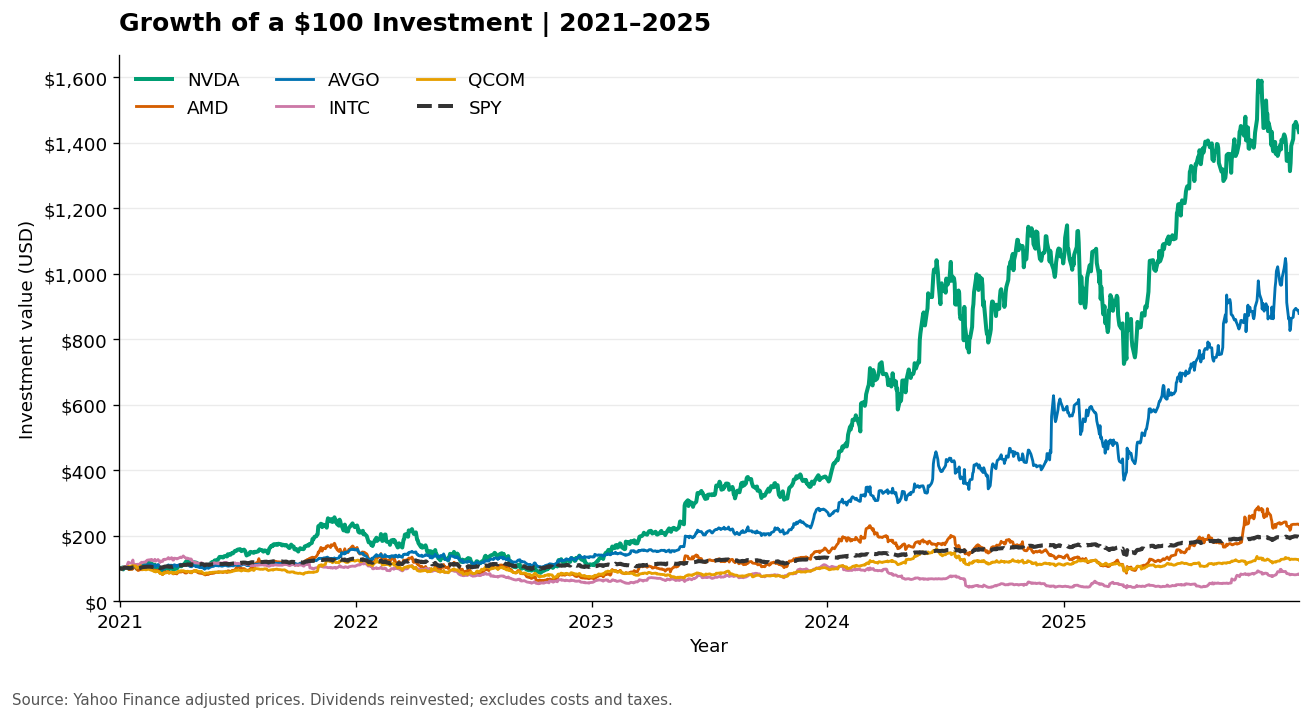

In [73]:
initial_investment = pd.DataFrame(
    100.0,
    index=pd.DatetimeIndex([baseline_date], name="Date"),
    columns=wealth_index.columns,
)

investment_growth = pd.concat([
    initial_investment,
    wealth_index * 100,
])

fig_growth, ax = plt.subplots()

for ticker in all_tickers:
    ax.plot(
        investment_growth.index,
        investment_growth[ticker],
        label=ticker,
        color=colors[ticker],
        linewidth=2.4 if ticker in ["NVDA", "SPY"] else 1.7,
        linestyle="--" if ticker == benchmark_ticker else "-",
    )

ax.set_title("Growth of a $100 Investment | 2021–2025", loc="left", pad=15)
ax.set_xlabel("Year")
ax.set_ylabel("Investment value (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(investment_growth.index.min(), investment_growth.index.max())
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, ncol=3, loc="upper left")

fig_growth.text(
    0.01, 0.01,
    "Source: Yahoo Finance adjusted prices. Dividends reinvested; excludes costs and taxes.",
    fontsize=9,
    color="#555555",
)

fig_growth.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [74]:
ending_values = (
    investment_growth.iloc[-1]
    .sort_values(ascending=False)
    .to_frame("Ending value of $100")
)

display(ending_values.style.format("${:,.2f}"))

assert np.allclose(
    investment_growth.iloc[0].to_numpy(), 100
), "All investments should start at $100."

assert np.allclose(
    investment_growth.iloc[-1].to_numpy(),
    ((1 + total_return) * 100).to_numpy(),
), "Ending values do not match total returns."

,Ending value of $100
Ticker,
NVDA,"$1,432.59"
AVGO,$878.66
AMD,$233.52
SPY,$195.39
QCOM,$125.05
INTC,$81.93


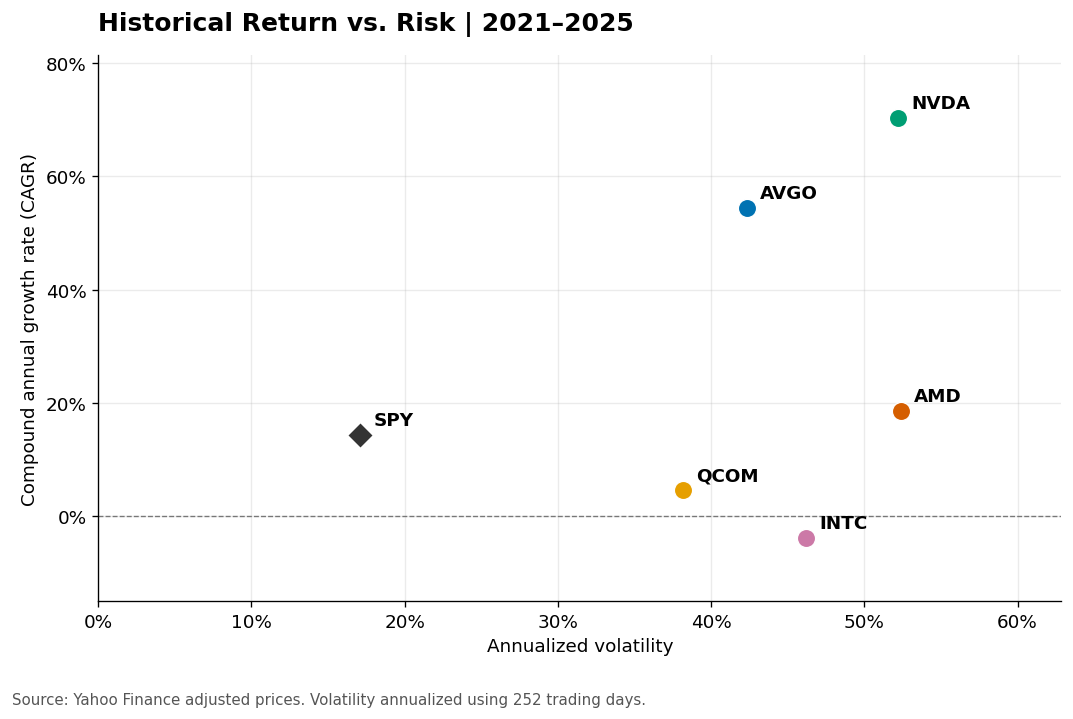

In [75]:
fig_risk_return, ax = plt.subplots(figsize=(9, 6))

for ticker in all_tickers:
    x = performance_summary.loc[ticker, "Annualized volatility"]
    y = performance_summary.loc[ticker, "CAGR"]

    ax.scatter(
        x, y,
        color=colors[ticker],
        s=120,
        marker="D" if ticker == benchmark_ticker else "o",
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )

    ax.annotate(
        ticker,
        (x, y),
        xytext=(8, 6),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title("Historical Return vs. Risk | 2021–2025", loc="left", pad=15)
ax.set_xlabel("Annualized volatility")
ax.set_ylabel("Compound annual growth rate (CAGR)")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.axhline(0, color="#777777", linewidth=0.8, linestyle="--")
ax.set_xlim(left=0, right=annualized_volatility.max() * 1.20)
ax.margins(y=0.15)
ax.grid(alpha=0.25)

fig_risk_return.text(
    0.01, 0.01,
    "Source: Yahoo Finance adjusted prices. Volatility annualized using 252 trading days.",
    fontsize=9,
    color="#555555",
)

fig_risk_return.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Drawdowns and rolling risk-adjusted performance

Drawdowns measure the decline from each investment's previous peak
within the study period. All panels use the same percentage scale.

Rolling Sharpe ratios use trailing windows of 252 trading observations,
approximately one year. Each estimate uses only returns through its
displayed date and requires a complete window.

Adjacent windows overlap substantially, so rolling estimates are not
independent observations.

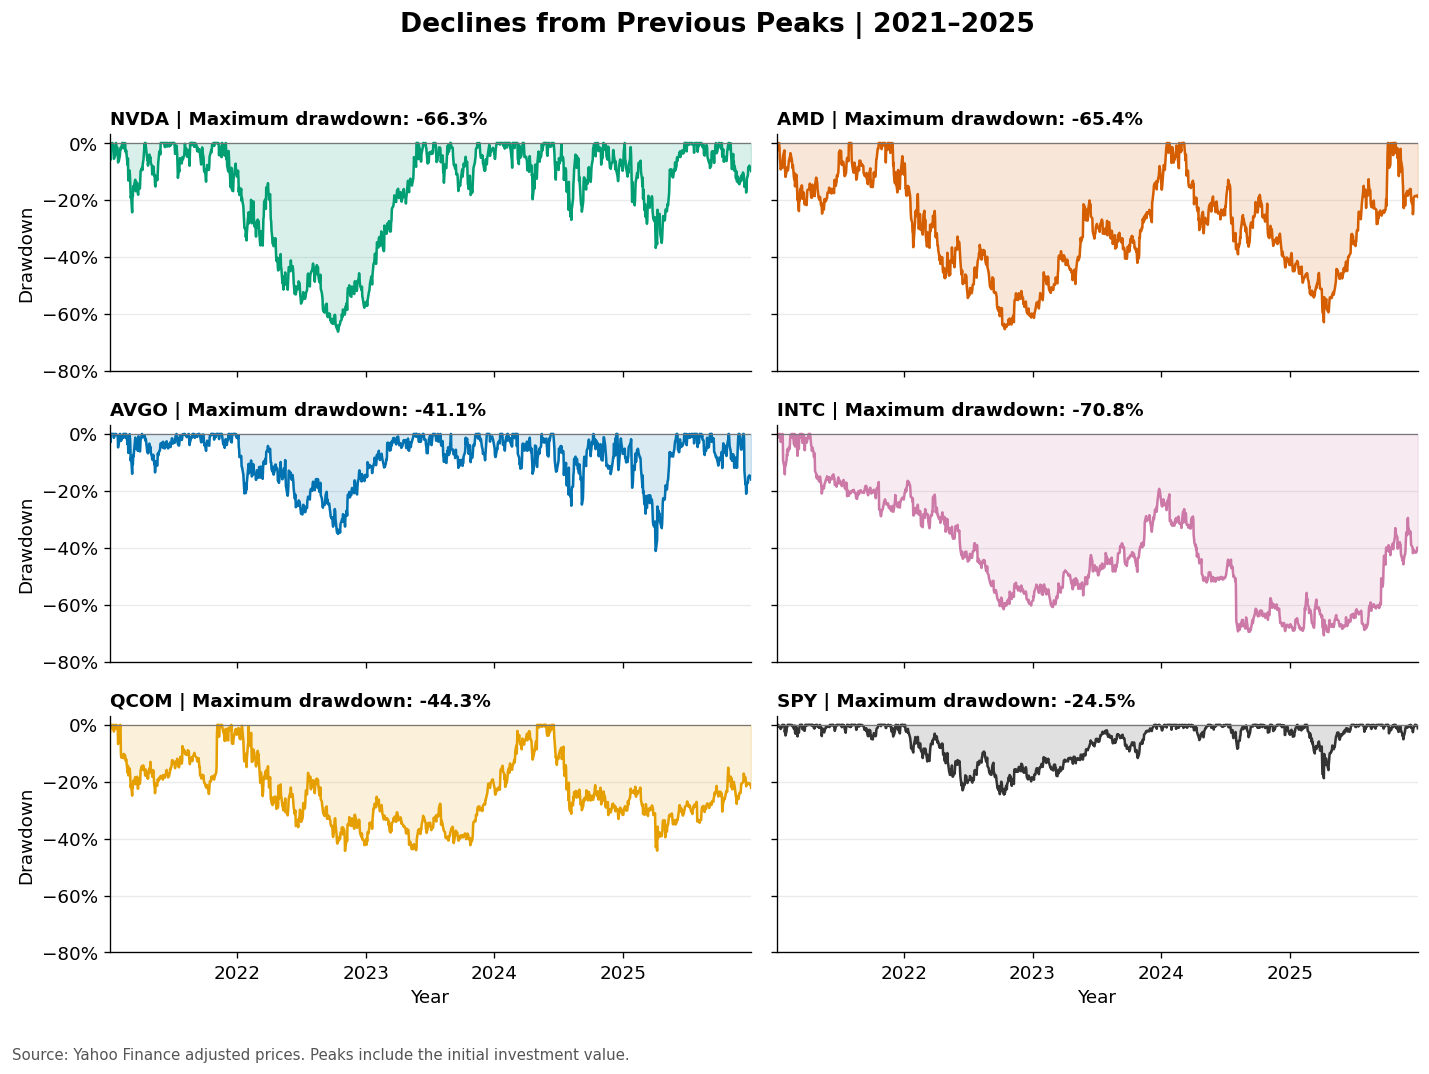

In [76]:
fig_drawdowns, axes = plt.subplots(
    3, 2,
    figsize=(12, 9),
    sharex=True,
    sharey=True,
)

lower_limit = np.floor(max_drawdown.min() * 10) / 10

for ax, ticker in zip(axes.flat, all_tickers):
    series = drawdowns[ticker]

    ax.plot(
        series.index,
        series,
        color=colors[ticker],
        linewidth=1.5,
    )

    ax.fill_between(
        series.index,
        series.to_numpy(),
        0,
        color=colors[ticker],
        alpha=0.15,
    )

    ax.set_title(
        f"{ticker} | Maximum drawdown: {max_drawdown[ticker]:.1%}",
        loc="left",
        fontsize=11,
    )

    ax.set_ylim(lower_limit, 0.03)
    ax.set_xlim(drawdowns.index.min(), drawdowns.index.max())
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.axhline(0, color="#777777", linewidth=0.7)
    ax.grid(axis="y", alpha=0.25)

for ax in axes[:, 0]:
    ax.set_ylabel("Drawdown")

for ax in axes[-1, :]:
    ax.set_xlabel("Year")

fig_drawdowns.suptitle(
    "Declines from Previous Peaks | 2021–2025",
    fontsize=16,
    fontweight="bold",
)

fig_drawdowns.text(
    0.01, 0.01,
    "Source: Yahoo Finance adjusted prices. Peaks include the initial investment value.",
    fontsize=9,
    color="#555555",
)

fig_drawdowns.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()

In [77]:
rolling_window = 252

rolling_mean = excess_returns.rolling(
    window=rolling_window,
    min_periods=rolling_window,
).mean()

rolling_std = excess_returns.rolling(
    window=rolling_window,
    min_periods=rolling_window,
).std(ddof=1)

rolling_sharpe = (
    rolling_mean
    / rolling_std.where(rolling_std > 0)
    * np.sqrt(trading_days_per_year)
)

rolling_sharpe_valid = rolling_sharpe.iloc[rolling_window - 1:]

assert np.isfinite(
    rolling_sharpe_valid.to_numpy()
).all(), "Invalid Sharpe ratios found after the initial window."

print("First rolling estimate:", rolling_sharpe_valid.index[0].date())
print("Last rolling estimate:", rolling_sharpe_valid.index[-1].date())
print("Number of rolling estimates:", len(rolling_sharpe_valid))

First rolling estimate: 2021-12-31
Last rolling estimate: 2025-12-31
Number of rolling estimates: 1004


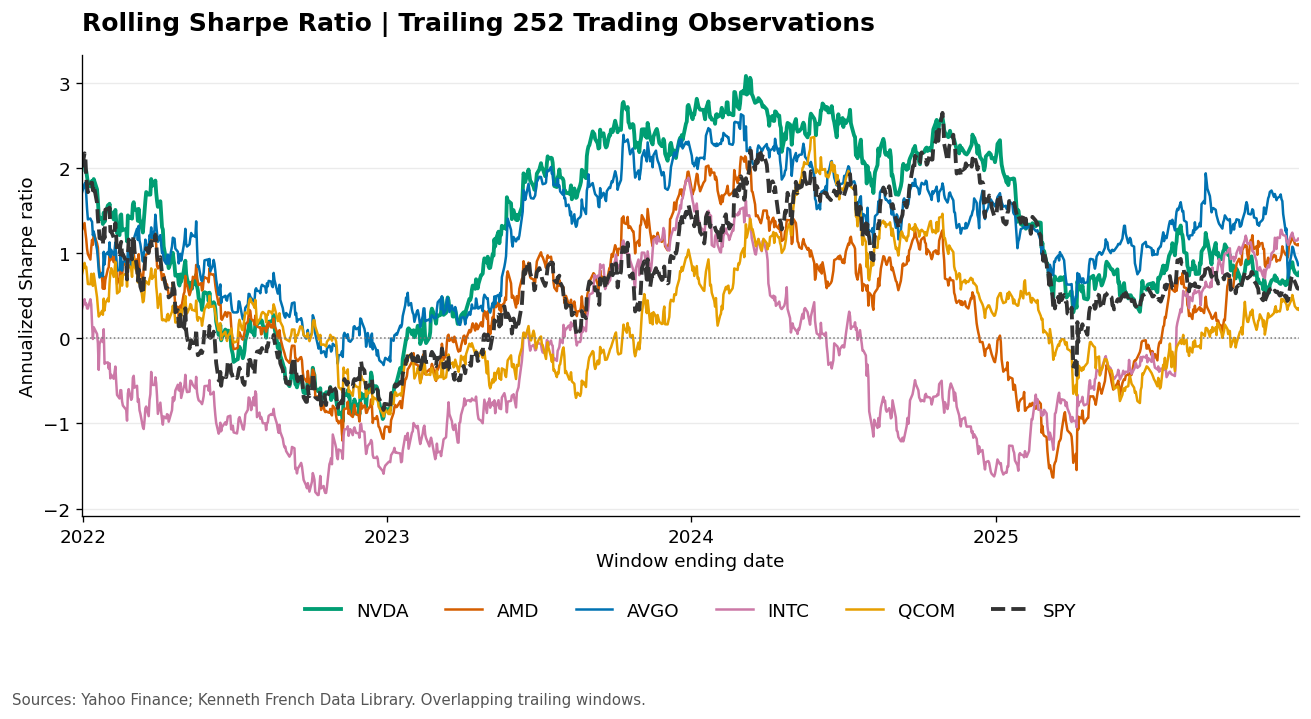

In [78]:
fig_rolling_sharpe, ax = plt.subplots(figsize=(11, 6))

for ticker in all_tickers:
    ax.plot(
        rolling_sharpe_valid.index,
        rolling_sharpe_valid[ticker],
        label=ticker,
        color=colors[ticker],
        linewidth=2.3 if ticker in ["NVDA", "SPY"] else 1.5,
        linestyle="--" if ticker == benchmark_ticker else "-",
    )

ax.set_title(
    "Rolling Sharpe Ratio | Trailing 252 Trading Observations",
    loc="left",
    pad=15,
)

ax.set_xlabel("Window ending date")
ax.set_ylabel("Annualized Sharpe ratio")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(
    rolling_sharpe_valid.index.min(),
    rolling_sharpe_valid.index.max(),
)
ax.axhline(0, color="#777777", linewidth=0.9, linestyle=":")
ax.grid(axis="y", alpha=0.25)

ax.legend(
    frameon=False,
    ncol=6,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
)

fig_rolling_sharpe.text(
    0.01, 0.01,
    "Sources: Yahoo Finance; Kenneth French Data Library. Overlapping trailing windows.",
    fontsize=9,
    color="#555555",
)

fig_rolling_sharpe.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [79]:
last_window = excess_returns.iloc[-rolling_window:]

last_window_sharpe = (
    last_window.mean()
    / last_window.std(ddof=1)
    * np.sqrt(trading_days_per_year)
)

assert np.allclose(
    rolling_sharpe_valid.iloc[-1].to_numpy(),
    last_window_sharpe.to_numpy(),
), "The final rolling estimate does not match the direct calculation."

assert np.allclose(
    drawdowns.min().to_numpy(),
    performance_summary["Maximum drawdown"].to_numpy(),
), "Drawdown charts do not match the performance summary."

print("All chart calculation checks passed.")

display(
    last_window_sharpe
    .sort_values(ascending=False)
    .to_frame("Final trailing-window Sharpe ratio")
    .style.format("{:.2f}")
)

All chart calculation checks passed.


,Final trailing-window Sharpe ratio
Ticker,
INTC,1.17
AMD,1.09
AVGO,0.86
NVDA,0.77
SPY,0.60
QCOM,0.34


## Calendar-year performance

Calendar-year returns compound daily adjusted returns within each year.
Annualized Sharpe ratios are calculated separately using each year's
daily excess returns and the same 252-day annualization convention.

These comparisons assess whether full-period results are consistent
across years. Annual estimates use fewer observations and may be less
stable than full-period estimates.

In [80]:
annual_returns = (
    (1 + daily_returns)
    .groupby(daily_returns.index.year)
    .prod()
    - 1
)

annual_returns.index.name = "Year"

display(
    annual_returns.style
    .format("{:.2%}")
    .highlight_max(axis=1, color="#D9EAD3")
)

Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Year,,,,,,
2021,125.48%,56.91%,56.48%,6.05%,22.25%,28.73%
2022,-50.26%,-54.99%,-13.27%,-46.64%,-38.58%,-18.18%
2023,239.02%,127.59%,104.18%,94.56%,35.07%,26.18%
2024,171.25%,-18.06%,110.49%,-59.57%,8.31%,24.89%
2025,38.92%,77.30%,50.63%,84.04%,13.84%,17.72%


In [81]:
annual_excess_mean = excess_returns.groupby(
    excess_returns.index.year
).mean()

annual_excess_std = excess_returns.groupby(
    excess_returns.index.year
).std(ddof=1)

annual_sharpe = (
    annual_excess_mean
    / annual_excess_std
    * np.sqrt(trading_days_per_year)
)

annual_sharpe.index.name = "Year"

display(
    annual_sharpe.style
    .format("{:.2f}")
    .highlight_max(axis=1, color="#D9EAD3")
)

Ticker,NVDA,AMD,AVGO,INTC,QCOM,SPY
Year,,,,,,
2021,2.03,1.27,1.71,0.35,0.76,2.01
2022,-0.81,-1.03,-0.23,-1.49,-0.84,-0.76
2023,2.67,1.89,2.24,1.81,0.96,1.47
2024,2.07,-0.28,1.55,-1.59,0.27,1.43
2025,0.81,1.16,0.95,1.19,0.40,0.68


In [82]:
annual_leaders = pd.DataFrame({
    "Highest-return stock": annual_returns[stock_tickers].idxmax(axis=1),
    "Highest stock return": annual_returns[stock_tickers].max(axis=1),
    "Highest-Sharpe stock": annual_sharpe[stock_tickers].idxmax(axis=1),
    "Highest stock Sharpe": annual_sharpe[stock_tickers].max(axis=1),
    "SPY Sharpe": annual_sharpe[benchmark_ticker],
    "NVDA Sharpe rank among stocks": annual_sharpe[stock_tickers].rank(
        axis=1,
        ascending=False,
        method="min",
    )["NVDA"],
})

display(
    annual_leaders.style.format({
        "Highest stock return": "{:.2%}",
        "Highest stock Sharpe": "{:.2f}",
        "SPY Sharpe": "{:.2f}",
        "NVDA Sharpe rank among stocks": "{:.0f}",
    })
)

,Highest-return stock,Highest stock return,Highest-Sharpe stock,Highest stock Sharpe,SPY Sharpe,NVDA Sharpe rank among stocks
Year,,,,,,
2021,NVDA,125.48%,NVDA,2.03,2.01,1
2022,AVGO,-13.27%,AVGO,-0.23,-0.76,2
2023,NVDA,239.02%,NVDA,2.67,1.47,1
2024,NVDA,171.25%,NVDA,2.07,1.43,1
2025,INTC,84.04%,INTC,1.19,0.68,4


In [83]:
annual_observation_counts = daily_returns.groupby(
    daily_returns.index.year
).size()

annual_observation_counts.index.name = "Year"

display(
    annual_observation_counts.to_frame("Trading observations")
)

reconstructed_total_return = (1 + annual_returns).prod() - 1

assert annual_returns.index.tolist() == [
    2021, 2022, 2023, 2024, 2025
], "Unexpected years in the annual table."

assert annual_observation_counts.sum() == len(daily_returns), (
    "Annual observation counts do not match the full dataset."
)

assert np.isfinite(annual_returns.to_numpy()).all(), (
    "Invalid annual returns found."
)

assert np.isfinite(annual_sharpe.to_numpy()).all(), (
    "Invalid annual Sharpe ratios found."
)

assert np.allclose(
    reconstructed_total_return.to_numpy(),
    total_return.to_numpy(),
), "Annual returns do not compound to the full-period return."

print("All calendar-year checks passed.")

,Trading observations
Year,
2021,252
2022,251
2023,250
2024,252
2025,250


All calendar-year checks passed.


## Benchmark sensitivity: SPY versus SOXX

The iShares Semiconductor ETF (SOXX) provides an alternative industry
benchmark to the broad-market SPY benchmark.

Beta and annualized tracking error are calculated against both
benchmarks using identical stock return dates and methods.

SOXX is an investable sector proxy, not an independent control group.
Its holdings can overlap with the stocks being evaluated, and its
composition and weights can change over time.

Changing the equity benchmark does not change the stocks' Sharpe
ratios, which remain measured relative to the risk-free return.

In [84]:
sector_ticker = "SOXX"

sector_raw = yf.download(
    tickers=sector_ticker,
    start=download_start,
    end=end_date,
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    keepna=True,
    progress=False,
)

if sector_raw is None or sector_raw.empty:
    raise ValueError("No SOXX data downloaded. Check the download messages.")

sector_prices = sector_raw["Adj Close"].sort_index().rename(sector_ticker)

assert sector_prices.index.is_unique, "Duplicate SOXX dates found."
assert np.isfinite(sector_prices.to_numpy()).all(), "Invalid SOXX prices found."
assert (sector_prices > 0).all(), "SOXX prices must be positive."

sector_retrieved_at = pd.Timestamp.now(tz="UTC").isoformat()

print("SOXX data retrieved at:", sector_retrieved_at)
display(sector_prices.head().to_frame())
display(sector_prices.tail().to_frame())

SOXX data retrieved at: 2026-11-15T04:08:23.247786+00:00


,SOXX
Date,
2020-12-28,39.649666
2020-12-29,39.547546
2020-12-30,40.210312
2020-12-31,40.337963
2021-01-04,40.168819


,SOXX
Date,
2025-12-24,101.868835
2025-12-26,101.835556
2025-12-29,101.595970
2025-12-30,101.462875
2025-12-31,100.208389


In [85]:
sector_returns = sector_prices.pct_change(
    fill_method=None
).reindex(daily_returns.index)

sector_returns.name = sector_ticker

assert sector_returns.index.equals(daily_returns.index), (
    "SOXX dates do not match the study dates."
)

assert np.isfinite(sector_returns.to_numpy()).all(), (
    "Missing or invalid SOXX returns found."
)

assert (sector_returns > -1).all(), (
    "A SOXX return of -100% or lower requires investigation."
)

print("Matched observations:", len(sector_returns))
print("First return date:", sector_returns.index.min().date())
print("Last return date:", sector_returns.index.max().date())
print("Missing values:", sector_returns.isna().sum())

display(sector_returns.head().to_frame().style.format("{:.2%}"))

Matched observations: 1255
First return date: 2021-01-04
Last return date: 2025-12-31
Missing values: 0


,SOXX
Date,
2021-01-04 00:00:00,-0.42%
2021-01-05 00:00:00,2.04%
2021-01-06 00:00:00,-0.32%
2021-01-07 00:00:00,3.77%
2021-01-08 00:00:00,0.05%


In [86]:
sector_excess = sector_returns - rf_daily
sector_variance = sector_excess.var(ddof=1)

assert sector_variance > 0, "SOXX excess-return variance must be positive."

beta_vs_sector = excess_returns[stock_tickers].apply(
    lambda column: column.cov(sector_excess) / sector_variance
)

active_returns_vs_sector = daily_returns[stock_tickers].sub(
    sector_returns,
    axis=0,
)

tracking_error_vs_sector = (
    active_returns_vs_sector.std(ddof=1)
    * np.sqrt(trading_days_per_year)
)

In [87]:
benchmark_comparison = pd.DataFrame({
    "Beta vs SPY": beta.loc[stock_tickers],
    "Beta vs SOXX": beta_vs_sector,
    "Tracking error vs SPY": tracking_error.loc[stock_tickers],
    "Tracking error vs SOXX": tracking_error_vs_sector,
})

benchmark_comparison.index.name = "Ticker"

display(
    benchmark_comparison.style.format({
        "Beta vs SPY": "{:.2f}",
        "Beta vs SOXX": "{:.2f}",
        "Tracking error vs SPY": "{:.2%}",
        "Tracking error vs SOXX": "{:.2%}",
    })
)

,Beta vs SPY,Beta vs SOXX,Tracking error vs SPY,Tracking error vs SOXX
Ticker,,,,
NVDA,2.13,1.19,42.07%,31.16%
AMD,2.01,1.17,43.10%,32.04%
AVGO,1.61,0.93,33.73%,26.15%
INTC,1.43,0.79,39.90%,37.47%
QCOM,1.56,0.88,28.94%,22.10%


In [88]:
sector_self_beta = (
    sector_excess.cov(sector_excess) / sector_variance
)

sector_self_tracking_error = (
    (sector_returns - sector_returns).std(ddof=1)
    * np.sqrt(trading_days_per_year)
)

sector_price_return = (
    sector_prices.loc[final_date]
    / sector_prices.loc[baseline_date]
    - 1
)

sector_compounded_return = (1 + sector_returns).prod() - 1

assert np.isfinite(benchmark_comparison.to_numpy()).all(), (
    "Invalid values in the benchmark comparison."
)

assert (tracking_error_vs_sector >= 0).all(), (
    "Tracking error cannot be negative."
)

assert np.isclose(sector_self_beta, 1.0), (
    "SOXX's beta relative to itself should equal 1."
)

assert np.isclose(sector_self_tracking_error, 0.0), (
    "SOXX's tracking error relative to itself should equal 0."
)

assert np.isclose(sector_compounded_return, sector_price_return), (
    "SOXX compounded returns do not match the adjusted-price calculation."
)

print("All benchmark comparison checks passed.")

All benchmark comparison checks passed.


## Key findings

### NVIDIA led over the full period, with substantial risk

Between 2021 and 2025, NVIDIA delivered a cumulative return of
1,332.59% and a CAGR of 70.30%. Its annualized Sharpe ratio of 1.22
was the highest among the selected stocks and SPY.

However, NVIDIA also recorded annualized volatility of 52.20% and
a maximum drawdown of 66.34%. Its strong five-year performance
therefore came with substantial fluctuations and a deep interim loss.

### Broadcom offered a different historical risk-return trade-off

Broadcom achieved a CAGR of 54.44% and a Sharpe ratio of 1.16,
compared with NVIDIA's 70.30% and 1.22.

Broadcom's annualized volatility was lower at 42.32%, and its maximum
drawdown was shallower at 41.15%. Its slightly lower Sharpe ratio
should be considered alongside these differences in risk.

### Performance leadership changed across years

NVIDIA had the highest Sharpe ratio among the five stocks in 2021,
2023 and 2024. Broadcom led in 2022, while Intel led in 2025.
NVIDIA ranked fourth among the stocks by Sharpe ratio in 2025.

The full-period leader was therefore not the leader in every year.
Rolling Sharpe ratios also showed that relative performance changed
over time.

### Benchmark choice changed the interpretation of risk

NVIDIA's beta was 2.13 against SPY and 1.19 against SOXX. Its
annualized tracking error fell from 42.07% against SPY to 31.16%
against SOXX.

All five stocks had lower tracking error against SOXX than against
SPY. Their return differences were less variable relative to the
semiconductor benchmark.

These changes reflect the reference benchmark, not a change in the
stocks' own volatility or Sharpe ratios.

## Conclusion

NVIDIA delivered the strongest full-period growth and the highest
historical Sharpe ratio in this comparison. Its lead was accompanied
by high volatility, a substantial drawdown and changes in annual
performance rankings.

Broadcom combined strong historical growth with lower volatility
and a shallower drawdown than NVIDIA, while achieving a similar
full-period Sharpe ratio. The results therefore highlight a trade-off
between realized growth and the losses experienced along the way.

For comparative screening, NVIDIA and Broadcom warrant further
investigation for different reasons: NVIDIA for its historical growth,
and Broadcom for its combination of growth and lower observed risk.

This analysis does not establish which stock will perform best in
the future or whether either is attractively priced today. A current
investment decision would also require valuation, business analysis
and consideration of the investor's objectives and risk tolerance.

## Limitations

- **Historical scope:** Results describe 2021–2025. They do not predict
  future returns, volatility or drawdowns.

- **Selection bias:** NVIDIA and the comparison companies were chosen
  retrospectively. This is not a universe selected using information
  available at the start of 2021, and it excludes firms that did not
  survive or were not selected.

- **Peer differences:** The companies differ in products, customers,
  business models and revenue exposures. They are an industry
  comparison group rather than identical businesses.

- **Estimation uncertainty:** The 95% bootstrap confidence interval for the NVIDIA–Broadcom Sharpe ratio difference spans zero (−0.645 to 0.769). The five-year sample is consistent with either stock having the higher Sharpe ratio. The interval depends on the choice of a 20-trading-day block length.

- **Benchmark dependence:** Beta and tracking error depend on the
  benchmark. SOXX can hold the stocks being evaluated, and its
  holdings, weights and index methodology can change over time.

- **Risk-free proxy:** Sharpe ratios use the Kenneth French daily
  risk-free return series. Source rounding and the choice of
  risk-free proxy can affect the estimates.

- **Annualization assumptions:** Volatility and Sharpe ratios use
  square-root-of-time scaling with 252 trading days. This is an
  approximation when returns exhibit serial dependence or changing
  volatility.

- **Overlapping windows:** Adjacent rolling Sharpe estimates share
  most of their observations and should not be treated as independent
  evidence.

- **Data and implementation:** Adjusted prices are obtained from a
  third-party source and may be revised. Results assume dividend
  reinvestment and exclude investor transaction costs and taxes.
  ETF returns reflect fund expenses.

- **Incomplete investment assessment:** The analysis does not evaluate
  valuation, earnings quality, competitive position or portfolio
  diversification. Historical volatility and drawdown do not capture
  every source of investment risk.

## Export results

Charts and summary tables are exported for portfolio presentation.
Package versions and data retrieval timestamps document the analysis
environment. Source data are downloaded by the notebook rather than
included in the exported package.

Percentage-based measures in the CSV files are stored as decimals.
Sharpe ratios and betas are unitless.

In [89]:
from pathlib import Path

project_dir = Path("nvidia-peer-analysis")
figures_dir = project_dir / "figures"
results_dir = project_dir / "results"

figures_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print("Export folder:", project_dir.resolve())

Export folder: /content/nvidia-peer-analysis


In [90]:
figures_to_export = {
    "investment_growth.png": fig_growth,
    "risk_return.png": fig_risk_return,
    "drawdowns.png": fig_drawdowns,
    "rolling_sharpe.png": fig_rolling_sharpe,
}

for filename, figure in figures_to_export.items():
    figure.savefig(
        figures_dir / filename,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

print(f"Exported {len(figures_to_export)} charts.")

Exported 4 charts.


In [91]:
sharpe_gap_summary = pd.DataFrame([{
    "comparison": "NVDA minus AVGO",
    "observed_sharpe_gap": observed_gap,
    "ci_95_lower": lower,
    "ci_95_upper": upper,
    "trading_days": n_days,
    "block_days": block_days,
    "bootstrap_samples": len(bootstrap_gaps),
    "method": "paired circular block bootstrap",
}]).set_index("comparison")

In [92]:
tables_to_export = {
    "performance_summary.csv": performance_summary,
    "sharpe_gap_bootstrap.csv": sharpe_gap_summary,
    "annual_returns.csv": annual_returns,
    "annual_sharpe.csv": annual_sharpe,
    "annual_leaders.csv": annual_leaders,
    "benchmark_comparison.csv": benchmark_comparison,
    "ending_investment_values.csv": ending_values,
}

for filename, table in tables_to_export.items():
    table.to_csv(results_dir / filename, float_format="%.10f")

print(f"Exported {len(tables_to_export)} results tables.")

Exported 7 results tables.


In [93]:
import json
import platform
from importlib.metadata import version

package_names = [
    "numpy",
    "pandas",
    "matplotlib",
    "yfinance",
    "jinja2",
    "ipython",
]

package_versions = {
    package: version(package)
    for package in package_names
}

analysis_packages = ["numpy", "pandas", "matplotlib", "yfinance", "jinja2"]

requirements_text = "\n".join(
    f"{package}=={package_versions[package]}"
    for package in analysis_packages
)

(project_dir / "requirements.txt").write_text(
    requirements_text + "\n",
    encoding="utf-8",
)

analysis_metadata = {
    "python_version": platform.python_version(),
    "package_versions": package_versions,
    "study_start": start_date,
    "study_end_exclusive": end_date,
    "stock_tickers": stock_tickers,
    "benchmarks": [benchmark_ticker, sector_ticker],
    "trading_observations": len(daily_returns),
    "annualization_factor": trading_days_per_year,
    "stock_data_retrieved_at": retrieved_at,
    "risk_free_data_retrieved_at": rf_retrieved_at,
    "sector_data_retrieved_at": sector_retrieved_at,
    "risk_free_source": rf_url,
}

(project_dir / "analysis_metadata.json").write_text(
    json.dumps(analysis_metadata, indent=2) + "\n",
    encoding="utf-8",
)

print(requirements_text)
print("\nSaved package versions and analysis metadata.")

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
yfinance==0.2.66
jinja2==3.1.6

Saved package versions and analysis metadata.


In [94]:
import shutil

expected_files = (
    [figures_dir / name for name in figures_to_export]
    + [results_dir / name for name in tables_to_export]
    + [
        project_dir / "requirements.txt",
        project_dir / "analysis_metadata.json",
    ]
)

for path in expected_files:
    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty export: {path}"
    )

for path in sorted(expected_files):
    print(path.relative_to(project_dir))

archive_path = shutil.make_archive(
    base_name=str(project_dir),
    format="zip",
    root_dir=str(project_dir.parent),
    base_dir=project_dir.name,
)

print(f"\nVerified {len(expected_files)} exported files.")
print("Created:", archive_path)

analysis_metadata.json
figures/drawdowns.png
figures/investment_growth.png
figures/risk_return.png
figures/rolling_sharpe.png
requirements.txt
results/annual_leaders.csv
results/annual_returns.csv
results/annual_sharpe.csv
results/benchmark_comparison.csv
results/ending_investment_values.csv
results/performance_summary.csv
results/sharpe_gap_bootstrap.csv

Verified 13 exported files.
Created: /content/nvidia-peer-analysis.zip


In [95]:
try:
    from google.colab import files
except ModuleNotFoundError:
    print(f"ZIP saved to {archive_path}")
else:
    files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>